# Домашнее задание "Продвинутая оптимизация".

### Задание

При фиксированном `seed=42` поэкспериментируйте с параметрами алгоритма [differential_evolution](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.differential_evolution.html): strategy, popsize, mutation.

Постройте графики количества итераций (`nit`) оптимизации [функции ackley](https://en.wikipedia.org/wiki/Ackley_function) от значения параметра.

Подробнее о результате выдачи [тут](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.OptimizeResult.html).

In [ ]:
import numpy as np
from scipy.optimize import differential_evolution
import matplotlib.pyplot as plt

%matplotlib inline

In [ ]:
def ackley(x):
    arg1 = -0.2 * np.sqrt(0.5 * (x[0] ** 2 + x[1] ** 2))
    arg2 = 0.5 * (np.cos(2. * np.pi * x[0]) + np.cos(2. * np.pi * x[1]))
    return -20. * np.exp(arg1) - np.exp(arg2) + 20. + np.e

bounds = [(-10, 10), (-10, 10)]

result = differential_evolution(ackley, bounds, seed=42)
result

             message: Optimization terminated successfully.
             success: True
                 fun: 4.440892098500626e-16
                   x: [ 0.000e+00  0.000e+00]
                 nit: 92
                nfev: 2853
          population: [[ 0.000e+00  0.000e+00]
                       [ 0.000e+00  0.000e+00]
                       ...
                       [ 0.000e+00  0.000e+00]
                       [ 0.000e+00  0.000e+00]]
 population_energies: [ 4.441e-16  4.441e-16 ...  4.441e-16  4.441e-16]

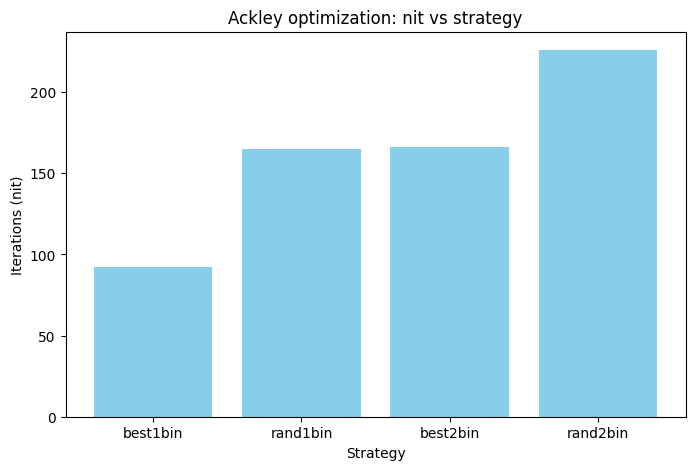

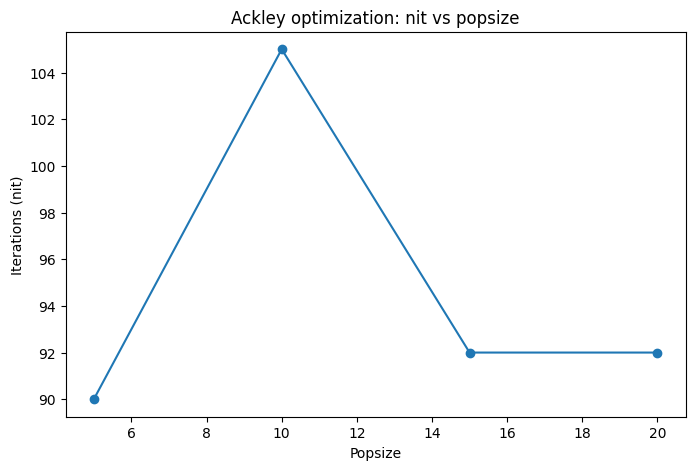

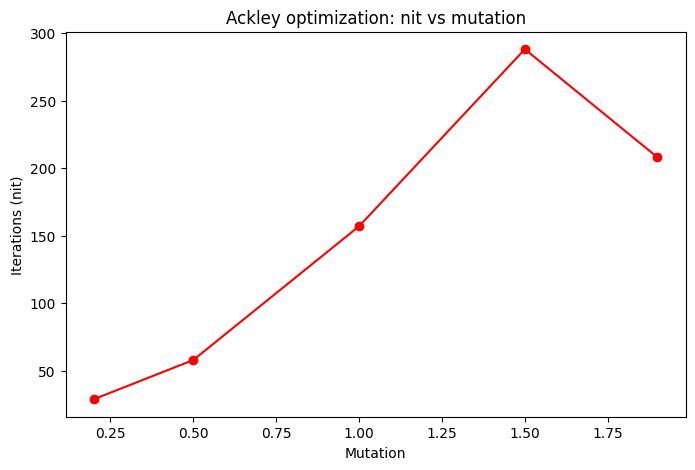

In [ ]:
### YOUR CODE HERE
# --- Эксперимент со strategy ---
strategies = ["best1bin", "rand1bin", "best2bin", "rand2bin"]
nit_values = []

for s in strategies:
    result = differential_evolution(ackley, bounds, strategy=s, seed=42)
    nit_values.append(result.nit)

plt.figure(figsize=(8,5))
plt.bar(strategies, nit_values, color="skyblue")
plt.xlabel("Strategy")
plt.ylabel("Iterations (nit)")
plt.title("Ackley optimization: nit vs strategy")
plt.show()

# --- Эксперимент с popsize ---
pop_sizes = [5, 10, 15, 20]
nit_values = []

for p in pop_sizes:
    result = differential_evolution(ackley, bounds, popsize=p, seed=42)
    nit_values.append(result.nit)

plt.figure(figsize=(8,5))
plt.plot(pop_sizes, nit_values, marker="o")
plt.xlabel("Popsize")
plt.ylabel("Iterations (nit)")
plt.title("Ackley optimization: nit vs popsize")
plt.show()

# --- Эксперимент с mutation ---
mutation_values = [0.2, 0.5, 1.0, 1.5, 1.9]
nit_values = []

for m in mutation_values:
    result = differential_evolution(ackley, bounds, mutation=m, seed=42)
    nit_values.append(result.nit)

plt.figure(figsize=(8,5))
plt.plot(mutation_values, nit_values, marker="o", color="red")
plt.xlabel("Mutation")
plt.ylabel("Iterations (nit)")
plt.title("Ackley optimization: nit vs mutation")
plt.show()


### Дополнительное задание


Поэкспериментируйте с параметрами и оптимизацией через [minimize](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.minimize.html):

In [ ]:
from scipy.optimize import minimize

x0 = [0,0]

result_m = minimize(ackley, x0,  method='Nelder-Mead')
result_m

       message: Optimization terminated successfully.
       success: True
        status: 0
           fun: 4.440892098500626e-16
             x: [ 0.000e+00  0.000e+00]
           nit: 8
          nfev: 17
 final_simplex: (array([[ 0.000e+00,  0.000e+00],
                       [-1.607e-05, -8.453e-06],
                       [-1.404e-06, -3.113e-05]]), array([ 4.441e-16,  5.136e-05,  8.816e-05]))

In [ ]:
### YOUR CODE HERE
methods = ["Nelder-Mead", "Powell", "BFGS"]
results = {}

for m in methods:
    res = minimize(ackley, [2, 2], method=m)  # стартуем не из (0,0), чтобы был смысл
    results[m] = res

for m, r in results.items():
    print(f"{m}: success={r.success}, nit={r.nit}, fun={r.fun}, x={r.x}")

Nelder-Mead: success=True, nit=27, fun=6.559645395501416, x=[1.97442506 1.97445789]
Powell: success=True, nit=8, fun=4.224620653303646e-12, x=[-1.08148211e-12 -1.03110177e-12]
BFGS: success=False, nit=3, fun=2.9557807312841078e-08, x=[-7.38945078e-09 -7.38945077e-09]


Вы также можете поэкспериментировать с [другими методами оптимизации](https://habr.com/ru/company/prequel/blog/568496/), но это не обязательно для зачета.
